# Li et al. (2023) ResNet50 — Adapted to BDRoad-Sense

**Goal:** reproduce the *training approach* of Li et al. as closely as practical, then evaluate it on our exact
`Normal` vs `Damaged` BDRoad-Sense split.

### Paper-faithful parts
- ResNet50 pretrained on ImageNet and fine-tuned.
- Binary road distress classification.
- 256×256 input for the binary task.
- Augmentation using rotation, lighting, zoom and vertical flip with probability 0.75.
- Batch normalization.
- Two dropout stages in the classification head (0.25 and 0.50).
- Weight decay = 0.001.
- Discriminative learning rates + One-Cycle schedule.
- Cyclical momentum between 0.95 and 0.85.
- Accuracy, Precision, Recall and F2 are reported; this notebook also reports F1 for our project comparison.

### Adaptations for our experiment
- Final output changed to **2 classes**: Normal / Damaged.
- We preserve our existing train/validation/test split instead of the paper's 80/20 split.
- The paper does not report exact discriminative LR boundaries or epoch count. We therefore use three LR groups
  `[1e-5, 1e-4, 1e-3]` and 15 epochs. These choices must be described as **adaptation settings**, not paper values.
- Augmentation ranges are implemented using a FastAI-style approximation because the paper reports the augmentation
  types and probability but not every numeric range.

In [2]:
from pathlib import Path
import os, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
DATA_DIR = Path("road_dataset_224")
CLASS_TO_IDX = {"Normal": 0, "Damaged": 1}
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for split in ["train", "val", "test"]:
    if not (DATA_DIR / split).exists():
        raise FileNotFoundError(f"Missing folder: {DATA_DIR / split}")

from torchvision.models import ResNet50_Weights

IMAGE_SIZE = 256
BATCH_SIZE = 32
EPOCHS = 15  # adaptation: epoch count not explicitly reported in Li et al.
MAX_LRS = [1e-5, 1e-4, 1e-3]  # adaptation: exact LR bounds not reported
WEIGHT_DECAY = 0.001

RESULTS_DIR = Path("results/li_resnet50")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = RESULTS_DIR / "best_li_resnet50.pth"

Device: cuda
GPU: NVIDIA GeForce RTX 5080


In [3]:
def remap_labels(dataset):
    dataset.samples = [
        (path, CLASS_TO_IDX[Path(path).parent.name])
        for path, _ in dataset.samples
    ]
    dataset.imgs = dataset.samples
    dataset.targets = [label for _, label in dataset.samples]
    dataset.class_to_idx = CLASS_TO_IDX.copy()
    dataset.classes = ["Normal", "Damaged"]
    return dataset

def load_split(split, transform):
    ds = datasets.ImageFolder(DATA_DIR / split, transform=transform)
    return remap_labels(ds)

def make_loaders(train_transform, eval_transform, batch_size):
    train_ds = load_split("train", train_transform)
    val_ds = load_split("val", eval_transform)
    test_ds = load_split("test", eval_transform)

    kwargs = dict(
        batch_size=batch_size,
        num_workers=0,
        pin_memory=torch.cuda.is_available()
    )
    train_loader = DataLoader(train_ds, shuffle=True, **kwargs)
    val_loader = DataLoader(val_ds, shuffle=False, **kwargs)
    test_loader = DataLoader(test_ds, shuffle=False, **kwargs)

    for name, ds in [("Train", train_ds), ("Validation", val_ds), ("Test", test_ds)]:
        counts = np.bincount(ds.targets, minlength=2)
        print(f"{name}: Normal={counts[0]}, Damaged={counts[1]}, Total={len(ds)}")
    return train_ds, val_ds, test_ds, train_loader, val_loader, test_loader

# Approximation of the augmentation recipe described in Li et al.
# The paper states rotation + lighting + zoom + vertical flip, randomly with p=0.75.
li_augmentation = transforms.RandomApply([
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomAffine(degrees=0, scale=(1.0, 1.1)),
    transforms.RandomVerticalFlip(p=1.0),
], p=0.75)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    li_augmentation,
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_ds, val_ds, test_ds, train_loader, val_loader, test_loader = make_loaders(
    train_transform, eval_transform, BATCH_SIZE
)

Train: Normal=928, Damaged=2470, Total=3398
Validation: Normal=198, Damaged=529, Total=727
Test: Normal=200, Damaged=531, Total=731


In [4]:
class AdaptiveConcatPool2d(nn.Module):
    """FastAI-style concat of adaptive max-pool and average-pool."""
    def __init__(self, size=1):
        super().__init__()
        self.ap = nn.AdaptiveAvgPool2d(size)
        self.mp = nn.AdaptiveMaxPool2d(size)

    def forward(self, x):
        return torch.cat([self.mp(x), self.ap(x)], dim=1)

class LiStyleResNet50(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        base = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V1)

        # Keep the convolutional ResNet backbone and replace its original classifier.
        self.conv1 = base.conv1
        self.bn1 = base.bn1
        self.relu = base.relu
        self.maxpool = base.maxpool
        self.layer1 = base.layer1
        self.layer2 = base.layer2
        self.layer3 = base.layer3
        self.layer4 = base.layer4

        # FastAI-style adaptive concat pooling + two-dropout classification head.
        self.pool = AdaptiveConcatPool2d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.BatchNorm1d(2048 * 2),
            nn.Dropout(0.25),
            nn.Linear(2048 * 2, 512),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(512),
            nn.Dropout(0.50),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x)
        return self.head(x)

model = LiStyleResNet50(num_classes=2).to(device)

# No explicit Softmax: CrossEntropyLoss consumes logits directly.
criterion = nn.CrossEntropyLoss()

# Discriminative learning rates: early / middle / late+head.
param_groups = [
    {
        "params": list(model.conv1.parameters()) + list(model.bn1.parameters()) +
                  list(model.layer1.parameters()) + list(model.layer2.parameters()),
        "lr": MAX_LRS[0],
    },
    {"params": model.layer3.parameters(), "lr": MAX_LRS[1]},
    {
        "params": list(model.layer4.parameters()) + list(model.head.parameters()),
        "lr": MAX_LRS[2],
    },
]

# Li et al. describe weight decay, cyclical momentum and One-Cycle training.
# The optimizer name is not explicitly reported in the paper; Adam is used here as a practical FastAI-style adaptation.
optimizer = torch.optim.Adam(
    param_groups,
    weight_decay=WEIGHT_DECAY,
    betas=(0.95, 0.999)
)

scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=MAX_LRS,
    epochs=EPOCHS,
    steps_per_epoch=len(train_loader),
    pct_start=0.3,
    anneal_strategy="cos",
    cycle_momentum=True,
    base_momentum=0.85,
    max_momentum=0.95,
)

print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to C:\Users\Mrym/.cache\torch\hub\checkpoints\resnet50-0676ba61.pth


100.0%


Total parameters: 25,615,938
Trainable parameters: 25,615,938


Epoch 01/15 | Train Loss: 0.4429 | Val Loss: 0.3935
Epoch 02/15 | Train Loss: 0.2751 | Val Loss: 0.1554
Epoch 03/15 | Train Loss: 0.2218 | Val Loss: 0.1165
Epoch 04/15 | Train Loss: 0.1851 | Val Loss: 0.4034
Epoch 05/15 | Train Loss: 0.1424 | Val Loss: 0.1668
Epoch 06/15 | Train Loss: 0.1539 | Val Loss: 0.1826
Epoch 07/15 | Train Loss: 0.1336 | Val Loss: 0.1652
Epoch 08/15 | Train Loss: 0.0989 | Val Loss: 0.1471
Epoch 09/15 | Train Loss: 0.0789 | Val Loss: 0.1050
Epoch 10/15 | Train Loss: 0.0709 | Val Loss: 0.1071
Epoch 11/15 | Train Loss: 0.0659 | Val Loss: 0.1070
Epoch 12/15 | Train Loss: 0.0465 | Val Loss: 0.0982
Epoch 13/15 | Train Loss: 0.0301 | Val Loss: 0.0950
Epoch 14/15 | Train Loss: 0.0274 | Val Loss: 0.0921
Epoch 15/15 | Train Loss: 0.0340 | Val Loss: 0.0933

Best epoch: 14 | Best validation loss: 0.0921
Training time: 4 min 50 sec


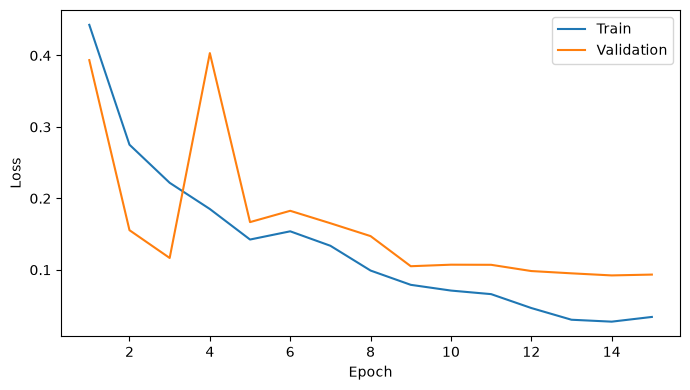

In [5]:
history = []
best_val_loss = float("inf")
best_epoch = 0

if device.type == "cuda":
    torch.cuda.synchronize()
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()

        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            val_loss += criterion(model(images), labels).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    history.append({
        "Epoch": epoch,
        "Train Loss": train_loss,
        "Validation Loss": val_loss,
        "LR early": optimizer.param_groups[0]["lr"],
        "LR middle": optimizer.param_groups[1]["lr"],
        "LR late": optimizer.param_groups[2]["lr"],
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}"
    )

if device.type == "cuda":
    torch.cuda.synchronize()
training_seconds = time.time() - start_time

print(f"\nBest epoch: {best_epoch} | Best validation loss: {best_val_loss:.4f}")
print(f"Training time: {int(training_seconds//60)} min {int(training_seconds%60)} sec")

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)
pd.DataFrame([{"Training Seconds": training_seconds}]).to_csv(
    RESULTS_DIR / "training_time.csv", index=False
)

plt.figure(figsize=(7, 4))
plt.plot(history_df["Epoch"], history_df["Train Loss"], label="Train")
plt.plot(history_df["Epoch"], history_df["Validation Loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=200)
plt.show()


Final Test Results
Accuracy: 0.9590
Precision: 0.9630
Recall: 0.9812
F1: 0.9720
F2: 0.9775

Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.90      0.92       200
     Damaged       0.96      0.98      0.97       531

    accuracy                           0.96       731
   macro avg       0.96      0.94      0.95       731
weighted avg       0.96      0.96      0.96       731



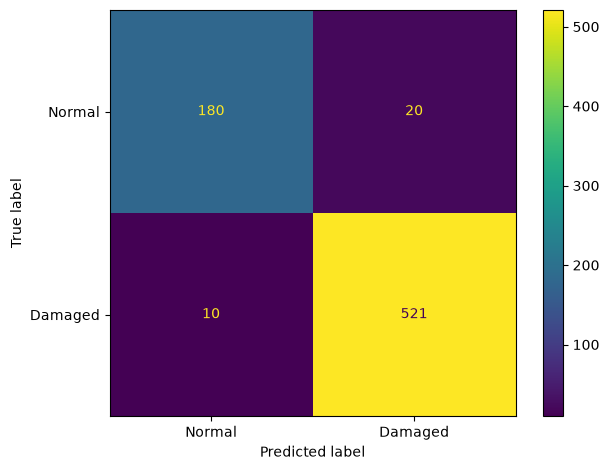


Robustness Results
                   Condition Accuracy Precision Recall     F1     F2
                       Clean   0.9590    0.9630 0.9812 0.9720 0.9775
        Low Brightness (0.7)   0.9521    0.9644 0.9699 0.9671 0.9688
       High Brightness (1.3)   0.9453    0.9521 0.9736 0.9628 0.9693
  Mild Blur (k=5, sigma=1.0)   0.9302    0.9800 0.9228 0.9505 0.9337
Strong Blur (k=9, sigma=2.0)   0.8112    0.9950 0.7439 0.8513 0.7834


In [6]:
def evaluate(model, loader):
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            preds = outputs.argmax(dim=1).cpu().numpy()
            y_pred.extend(preds)
            y_true.extend(labels.numpy())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F2": fbeta_score(y_true, y_pred, beta=2, pos_label=1, zero_division=0),
    }
    return metrics, np.array(y_true), np.array(y_pred)

def robustness_transform(image_size, brightness=1.0, blur=None):
    steps = [transforms.Resize((image_size, image_size))]
    if brightness != 1.0:
        steps.append(transforms.Lambda(lambda img, f=brightness: TF.adjust_brightness(img, f)))
    if blur is not None:
        kernel_size, sigma = blur
        steps.append(transforms.GaussianBlur(kernel_size=kernel_size, sigma=sigma))
    steps += [
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
    ]
    return transforms.Compose(steps)

ROBUSTNESS_CONDITIONS = {
    "Clean": {"brightness": 1.0, "blur": None},
    "Low Brightness (0.7)": {"brightness": 0.7, "blur": None},
    "High Brightness (1.3)": {"brightness": 1.3, "blur": None},
    "Mild Blur (k=5, sigma=1.0)": {"brightness": 1.0, "blur": (5, 1.0)},
    "Strong Blur (k=9, sigma=2.0)": {"brightness": 1.0, "blur": (9, 2.0)},
}

def run_robustness(model, image_size, batch_size):
    rows = []
    for condition, settings in ROBUSTNESS_CONDITIONS.items():
        ds = load_split("test", robustness_transform(image_size, **settings))
        loader = DataLoader(
            ds, batch_size=batch_size, shuffle=False, num_workers=0,
            pin_memory=torch.cuda.is_available()
        )
        metrics, _, _ = evaluate(model, loader)
        rows.append({"Condition": condition, **metrics})
    return pd.DataFrame(rows)

def show_and_save_results(model, test_loader, results_dir, image_size, batch_size):
    metrics, y_true, y_pred = evaluate(model, test_loader)

    print("\nFinal Test Results")
    for k in ["Accuracy", "Precision", "Recall", "F1", "F2"]:
        print(f"{k}: {metrics[k]:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["Normal", "Damaged"],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=["Normal", "Damaged"]).plot(values_format="d")
    plt.tight_layout()
    plt.savefig(results_dir / "confusion_matrix.png", dpi=200)
    plt.show()

    pd.DataFrame([metrics]).to_csv(results_dir / "clean_test_metrics.csv", index=False)

    robust = run_robustness(model, image_size=image_size, batch_size=batch_size)
    robust.to_csv(results_dir / "robustness_results.csv", index=False)

    print("\nRobustness Results")
    print(robust.to_string(
        index=False,
        formatters={c: "{:.4f}".format for c in ["Accuracy", "Precision", "Recall", "F1", "F2"]}
    ))
    return metrics, robust

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
test_metrics, robustness_results = show_and_save_results(
    model, test_loader, RESULTS_DIR, IMAGE_SIZE, BATCH_SIZE
)